[*********************100%***********************]  1 of 1 completed


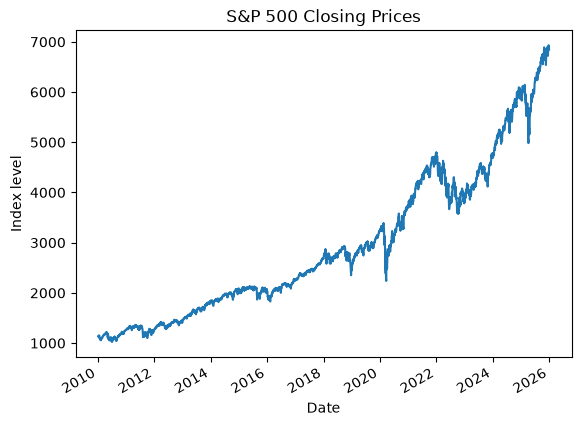

In [1]:
import yfinance as yf
import matplotlib.pyplot as plt
data = yf.download("^GSPC", start="2010-01-01", end="2026-01-01")
prices = data["Close"].squeeze()
prices.plot(title="S&P 500 Closing Prices")
plt.ylabel("Index level")
plt.show()



In [2]:
returns = prices.pct_change().dropna()
print(returns.head())
print("Number of returns:", len(returns))

Date
2010-01-05    0.003116
2010-01-06    0.000546
2010-01-07    0.004001
2010-01-08    0.002882
2010-01-11    0.001747
Name: ^GSPC, dtype: float64
Number of returns: 4023


In [3]:
mean = returns.mean()
std = returns.std()
var_99 = 2.326 * std - mean
print("Mean:", mean)
print("Standard Deviation:", std)
print("99% VaR:", var_99)


Mean: 0.0005069667735064549
Standard Deviation: 0.010916460326292989
99% VaR: 0.024884719945451036


In [4]:
breaches = returns[returns < -var_99]
breach_count = len(breaches)
breach_rate = breach_count / len(returns)
print("Expected breaches:", 0.01 * len(returns))
print("Actual breaches:", breach_count)
print("Breach rate:", breach_rate * 100, "%")

Expected breaches: 40.230000000000004
Actual breaches: 81
Breach rate: 2.013422818791946 %


In [5]:
import numpy as np
from scipy.stats import norm

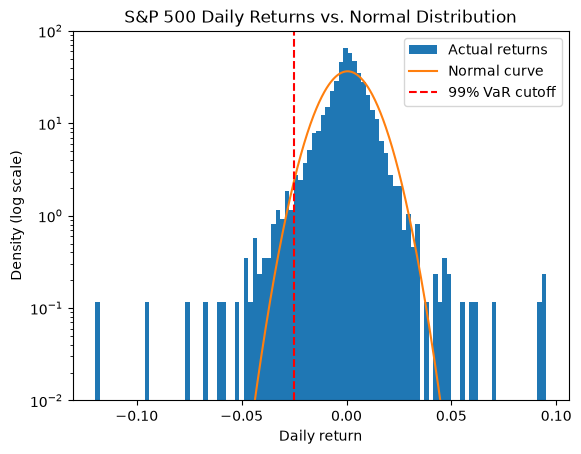

In [6]:
plt.hist(returns, bins=100, density=True, label="Actual returns")

x = np.linspace(returns.min(), returns.max(), 1000)
plt.plot(x, norm.pdf(x, mean, std), label="Normal curve")

plt.axvline(-var_99, color="red", linestyle="--", label="99% VaR cutoff")

plt.yscale("log")
plt.ylim(0.01, 100)
plt.title("S&P 500 Daily Returns vs. Normal Distribution")
plt.xlabel("Daily return")
plt.ylabel("Density (log scale)")
plt.legend()
plt.show()

In [7]:
## Part 2: Monthly VaR using the previous month's data

In [8]:
## use previous month's data to calculate the monthly VaR for the next month. For example, use January's data to calculate February's VaR. using the same month data would be called look-ahead bias.

In [9]:
import pandas as pd

month = returns.index.to_period("M")
monthly = returns.groupby(month).agg(["mean", "std"])
## groupby(month) puts days from the same month together. .agg(...) then calculates each group's mean and standard deviation.
previous = monthly.shift(1)
## The March row now holds February's numbers. The first row becomes empty because there's no earlier month.

monthly_var = 2.326 * previous["std"] - previous["mean"]
## gives one VaR for each month.
daily_var = pd.Series(monthly_var.reindex(month).to_numpy(),
                      index=returns.index).dropna()

test_returns = returns.loc[daily_var.index]
new_breaches = test_returns < -daily_var
old_breaches = test_returns < -var_99

print("Days tested:", len(test_returns))
print("Expected breaches:", 0.01 * len(test_returns))
print("Fixed VaR breach rate:", old_breaches.mean() * 100, "%")
print("Monthly VaR breaches:", new_breaches.sum())
print("Monthly VaR breach rate:", new_breaches.mean() * 100, "%")

Days tested: 4005
Expected breaches: 40.050000000000004
Fixed VaR breach rate: 2.0224719101123596 %
Monthly VaR breaches: 155
Monthly VaR breach rate: 3.870162297128589 %


In [13]:
## The monthly version did worse
## Part 3: 250-day rolling VaR:

In [12]:
roll_mean = returns.rolling(250).mean().shift(1)
roll_std = returns.rolling(250).std().shift(1)
roll_var = (2.326 * roll_std - roll_mean).dropna()

roll_returns = returns.loc[roll_var.index]
roll_breaches = roll_returns < -roll_var
monthly_same = roll_returns < -daily_var.loc[roll_var.index]
fixed_same = roll_returns < -var_99

print("Days tested:", len(roll_returns))
print("Rolling breaches:", roll_breaches.sum())
print("Rolling rate:", roll_breaches.mean() * 100, "%")
print("Monthly rate:", monthly_same.mean() * 100, "%")
print("Fixed rate:", fixed_same.mean() * 100, "%")

Days tested: 3773
Rolling breaches: 100
Rolling rate: 2.6504108136761197 %
Monthly rate: 3.869599787967135 %
Fixed rate: 1.9613040021203287 %


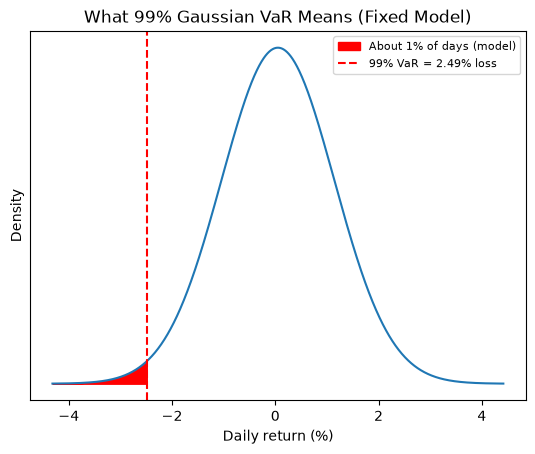

In [14]:
x = np.linspace(mean - 4*std, mean + 4*std, 1000)
y = norm.pdf(x, mean, std)

plt.plot(x * 100, y)
plt.fill_between(x * 100, y, where=(x < -var_99), color="red",
                 label="About 1% of days (model)")
plt.axvline(-var_99 * 100, color="red", linestyle="--",
            label=f"99% VaR = {var_99*100:.2f}% loss")

plt.title("What 99% Gaussian VaR Means (Fixed Model)")
plt.xlabel("Daily return (%)")
plt.ylabel("Density")
plt.yticks([])
plt.legend(loc="upper right", fontsize=8)
plt.show()